# Лаболаторная работа № 3. Оптимизация гиперпараметров.

Для анализа выберем 2-ую ЛР по классификации. Попытаемся оптимизировать параметры градиентного бустинга. Поэтому загрузим данные, создадим препроцессинг и создадим объект пайплайна из 2-ой ЛР.

In [205]:
# imports
import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import loguniform, randint, uniform
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.pipeline import Pipeline


In [194]:
models = {} # for basic, grid and random search

In [195]:
# consts

RANDOM_STATE = 42
TEST_SIZE = 0.2

AGE_GROUP_BOUNDARIES = (12, 18, 60, 100)
AGE_GROUP_NAMES = ('Child', 'Teen', 'Adult', 'Old')

DEF_ESTIMATORS = 200
DEF_LEARNING_RATE = 0.05
DEF_SUBSAMPLES = 0.8
DEF_MAX_DEPTH = 2
DEF_MIN_SAMPLE_LEAF = 5

ESTIMATORS_SEARCH_AREA = np.arange(75, 350, 25)
LEARNING_RATE_SEARCH_AREA = [0.1, 0.3, 0.5, 0.7] 
MAX_DEPTH_SEARCH_AREA = np.arange(1, 5+1, 1)
SUBSAMPLE_SEARCH_AREA = np.linspace(0.8, 1.0, 3)

RAND_ESTIMATORS_SEARCH_AREA = randint(50, 401)
RAND_LEARNING_RATE_SEARCH_AREA = loguniform(0.01, 0.8)
RAND_MAX_DEPTH_SEARCH_AREA = randint(1, 7)
RAND_SUBSAMPLE_SEARCH_AREA = uniform(0.7, 0.3)

FOLD_CNT = 5

VALIDATION_VALS_ESTIMATORS = [25, 50, 75, 100, 150, 200, 300, 400, 500]
VALIDATION_VALS_LEARNING_RATE =  [0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7]


In [196]:
df = pd.read_csv("./Titanic-Dataset.csv", sep=",")

In [197]:

X = df.drop(columns=['Survived'])
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)



In [198]:
class NonNameFeaturePreprocessor(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None): # type: ignore
        temp_df = X.copy() # type: ignore

        self.age_medians_ = temp_df.groupby(["Sex", "Pclass"])["Age"].median() # type: ignore
        self.global_age_median_ = temp_df["Age"].median() # type: ignore
        self.embarked_mode_ = temp_df["Embarked"].mode()[0] # type: ignore

        df = self._transform(X) # type: ignore

        self.feature_names_out_ = df.columns.tolist()

        return self

    def transform(self, X: pd.DataFrame):
        df = self._transform(X)

        df = df.reindex(columns=self.feature_names_out_, fill_value=0)

        return df

    def _transform(self, X: pd.DataFrame):
        df = X.copy()

        df["Embarked"] = df["Embarked"].fillna(self.embarked_mode_) # type: ignore

        def fill_age(row: pd.Series): # type: ignore
            if pd.isna(row["Age"]):
                key = (row["Sex"], row["Pclass"])
                if key in self.age_medians_.index and not pd.isna(self.age_medians_[key]): # type: ignore
                    return self.age_medians_[key] # type: ignore
                return self.global_age_median_ # type: ignore
            return row["Age"]

        def fill_age_group(row): # type: ignore
            for age, name in zip(AGE_GROUP_BOUNDARIES, AGE_GROUP_NAMES):
                if row["Age"] <= age:
                    row["Age_Group"] = name
                    break
            return row["Age_Group"] # type: ignore

        df["Age"] = df.apply(fill_age, axis=1)

        df["Age_Group"] = df.apply(fill_age_group, axis=1) # type: ignore

        df["Age"] = df["Age"].fillna(self.global_age_median_) # type: ignore

        df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
        df['IsAlone'] = df['FamilySize'] == 1

        df = df.drop(columns=["Cabin", "PassengerId", "Name", "Ticket", "Id"], errors="ignore")

        df = pd.get_dummies(df, columns=["Embarked", "Sex", "Age_Group"], prefix=["Embarked", "Sex", "Age_Group"])

        return df

    def get_feature_names_out(self, input_features=None): # type: ignore
        return self.feature_names_out_

preprocessor = NonNameFeaturePreprocessor()

In [199]:
gb = Pipeline([
    ("prep", preprocessor),
    ("model", GradientBoostingClassifier(
        n_estimators=DEF_ESTIMATORS,
        learning_rate=DEF_LEARNING_RATE,
        subsample=DEF_SUBSAMPLES,
        max_depth=DEF_MAX_DEPTH,
        min_samples_leaf=DEF_MIN_SAMPLE_LEAF,
        random_state=RANDOM_STATE
    ))
])

gb.fit(X_train, y_train)

pred = gb.predict(X_test)

print("Accuracy: ", accuracy_score(y_test, pred))
print("Precision: ", precision_score(y_test, pred))
print("Recall: ", recall_score(y_test, pred))
print("F1: ", f1_score(y_test, pred))

models["gb_def"] = copy.deepcopy(gb)

Accuracy:  0.8212290502793296
Precision:  0.8245614035087719
Recall:  0.6811594202898551
F1:  0.746031746031746


Будем оптимизировать learning rate, max depth, n_estimators, subsamples.

learning rate - то, на сколько мы исправляем ошибки предыдущего дерева (малое значение - недообучение, больше - переобучение), 0 - не исправляем, 1 - исправляем полностью. Будем перебирать в интервале [0.1; 0.5] с шагом 0.2 - 3 варианта.
max depth - ограничивает высоту дерева для регуляризации. Будем перебирать от 1 до 8 -> 8.
n estimators - количество деревьев, чем выше, тем сложнее модель, будем перебирать от 75 до 350 с шагом 25 -> 12.
subsample - доля данных из train, используемых для обучения деревьев. Это позволяет деревьям отличаться друг от друга. от 0.8 до 1.0 с шагом 0.1 -> 3 значения.

Всего 864 комбинации вариантов для GridSearch, с 5 фолдами, 4320 обучений. Для Random search пределы будут большими.

## GridSearchCV

In [200]:
param_grid = { # type: ignore
    "model__n_estimators": ESTIMATORS_SEARCH_AREA,
    "model__learning_rate": LEARNING_RATE_SEARCH_AREA,
    "model__max_depth": MAX_DEPTH_SEARCH_AREA,
    "model__subsample": SUBSAMPLE_SEARCH_AREA
}

grid = GridSearchCV(
    estimator=gb,
    param_grid=param_grid,
    scoring="f1",
    cv=StratifiedKFold(
        n_splits=FOLD_CNT,
        shuffle=True,
        random_state=RANDOM_STATE
    ),
    n_jobs=-1
)

grid.fit(X_train, y_train)

models["grid"] = copy.deepcopy(grid)

Было выбрано 5 фолдов, так как:
1) фолды имеют такой дефолтный параметр
2) трейн и тест дата содержат приемлимое количество данных (соответственно примерно 570 и 142)
3) На 5-ти видно то, как модель себя ведёт при разных данных train и насколько она стабильна

### Проверим результаты

In [201]:
results_grid = pd.DataFrame(grid.cv_results_).copy()

def diff(row: pd.Series):
    keys = (f"split{n}_test_score" for n in range(FOLD_CNT))
    values = tuple(row[key] for key in keys)
    return max(values) - min(values)

results_grid["max_diff"] = results_grid.apply(diff, axis=1)
results_grid = results_grid.sort_values("rank_test_score")

display(results_grid.head(20))
WORKLOAD_OF_GRID = results_grid.shape[0]
print(WORKLOAD_OF_GRID)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__learning_rate,param_model__max_depth,param_model__n_estimators,param_model__subsample,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score,max_diff
530,0.835858,0.087738,0.110587,0.020984,0.7,2,75,1.0,"{'model__learning_rate': 0.7, 'model__max_dept...",0.814815,0.767857,0.811881,0.728972,0.752475,0.775200,0.033533,1,0.085843
209,1.329869,0.373343,0.100357,0.036830,0.3,2,150,1.0,"{'model__learning_rate': 0.3, 'model__max_dept...",0.836364,0.738739,0.803922,0.742857,0.752475,0.774871,0.038619,2,0.097625
536,0.818424,0.036168,0.093018,0.023953,0.7,2,125,1.0,"{'model__learning_rate': 0.7, 'model__max_dept...",0.818182,0.752294,0.826923,0.722222,0.752475,0.774419,0.040908,3,0.104701
539,0.853008,0.046458,0.086859,0.022395,0.7,2,150,1.0,"{'model__learning_rate': 0.7, 'model__max_dept...",0.807339,0.763636,0.803922,0.745455,0.750000,0.774070,0.026477,4,0.061885
107,0.953181,0.128693,0.099878,0.031805,0.1,4,125,1.0,"{'model__learning_rate': 0.1, 'model__max_dept...",0.796296,0.766355,0.820000,0.733945,0.752475,0.773814,0.030787,5,0.086055
65,1.092912,0.168653,0.084451,0.015003,0.1,2,325,1.0,"{'model__learning_rate': 0.1, 'model__max_dept...",0.807339,0.733945,0.811881,0.747664,0.767677,0.773701,0.031254,6,0.077936
206,1.037230,0.206931,0.077112,0.005003,0.3,2,125,1.0,"{'model__learning_rate': 0.3, 'model__max_dept...",0.828829,0.738739,0.803922,0.735849,0.760000,0.773468,0.036864,7,0.092980
212,0.890407,0.107090,0.074273,0.003210,0.3,2,175,1.0,"{'model__learning_rate': 0.3, 'model__max_dept...",0.828829,0.733945,0.807692,0.735849,0.760000,0.773263,0.038457,8,0.094884
542,0.888094,0.124639,0.091459,0.023880,0.7,2,175,1.0,"{'model__learning_rate': 0.7, 'model__max_dept...",0.803738,0.722222,0.815534,0.733945,0.784314,0.771951,0.037364,9,0.093312
79,0.845828,0.065956,0.097009,0.042567,0.1,3,175,0.9,"{'model__learning_rate': 0.1, 'model__max_dept...",0.811321,0.733945,0.823529,0.727273,0.762887,0.771791,0.039327,10,0.096257


660


Как видно, для топ 1 модели разница между лучшей и худшей по метрике по cv составляет примерно 0.1, что довольно много, а значит модель на данных гиперпараметрах нестабильна (довольно глубокие деревья и малым количеством деревьев). Но посмотрим на rank 16 модель - у неё разница уже 0.062, что уже довольно приемлимо, а средний F1 не сильно ниже Rank 1 - в этой модели деревья - пни, но их больше, что и компенсирует их "глупость", так же у этой модели довольно больше коэффициент обучения, то есть много коротких деревьев быстро исправляют ошибки друг друга, при чём они различаются по трейну, так как $subsample \neq 1.0$.

Количество проверенных комбинаций - 660.

лучший набор:

1) learning rate = 0.5
2) max depth = 1
3) n estimators = 275
4) subsamples = 0.9

mean f1 - 0.77, std - 0.02, diff - 0.062
time - 4m 32s

## RandomSearchCV

In [202]:
param_grid = { # type: ignore
    "model__n_estimators": RAND_ESTIMATORS_SEARCH_AREA,
    "model__learning_rate": RAND_LEARNING_RATE_SEARCH_AREA,
    "model__max_depth": RAND_MAX_DEPTH_SEARCH_AREA,
    "model__subsample": RAND_SUBSAMPLE_SEARCH_AREA
}

rand = RandomizedSearchCV(
    estimator=gb,
    param_distributions=param_grid,
    scoring="f1",
    n_iter=WORKLOAD_OF_GRID,
    cv=StratifiedKFold(
        n_splits=FOLD_CNT,
        shuffle=True,
        random_state=RANDOM_STATE
    ),
    n_jobs=-1,
    random_state=RANDOM_STATE
)

rand.fit(X_train, y_train)

models["rand"] = copy.deepcopy(rand)

In [203]:
results_random = pd.DataFrame(rand.cv_results_).copy()

def diff(row: pd.Series):
    keys = (f"split{n}_test_score" for n in range(FOLD_CNT))
    values = tuple(row[key] for key in keys)
    return max(values) - min(values)

results_random["max_diff"] = results_random.apply(diff, axis=1)
results_random = results_random.sort_values("rank_test_score")

display(results_random.head(20))

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__learning_rate,param_model__max_depth,param_model__n_estimators,param_model__subsample,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score,max_diff
318,1.901133,0.196211,0.074924,0.002541,0.014796,6,344,0.963735,"{'model__learning_rate': 0.014796438154354958,...",0.800000,0.754717,0.811881,0.720721,0.780000,0.773464,0.032729,1,0.091160
546,1.266808,0.089398,0.095345,0.020247,0.030202,5,198,0.993519,"{'model__learning_rate': 0.030202115202650922,...",0.781818,0.759259,0.840000,0.715596,0.767677,0.772870,0.040197,2,0.124404
642,1.078721,0.296965,0.079685,0.009768,0.059847,4,191,0.971082,"{'model__learning_rate': 0.0598471829308856, '...",0.788991,0.770642,0.816327,0.727273,0.760000,0.772646,0.029657,3,0.089054
407,1.072764,0.113976,0.098024,0.031601,0.041578,4,213,0.990946,"{'model__learning_rate': 0.04157822595762901, ...",0.811321,0.754717,0.816327,0.710280,0.760000,0.770529,0.039376,4,0.106046
491,0.879601,0.186084,0.087875,0.017593,0.417194,2,61,0.979179,"{'model__learning_rate': 0.41719424774134395, ...",0.800000,0.745455,0.808081,0.740741,0.755102,0.769876,0.028392,5,0.067340
570,1.419223,0.101259,0.097679,0.028364,0.032621,4,354,0.890947,"{'model__learning_rate': 0.03262068757127685, ...",0.814815,0.732143,0.808081,0.715596,0.776699,0.769467,0.039736,6,0.099218
353,0.747613,0.138942,0.073316,0.007407,0.135266,4,56,0.719688,"{'model__learning_rate': 0.1352660499805479, '...",0.822430,0.745455,0.787879,0.720721,0.767677,0.768832,0.034923,7,0.101709
445,0.852272,0.176983,0.095622,0.022970,0.232623,3,70,0.758733,"{'model__learning_rate': 0.23262309830539354, ...",0.788991,0.754386,0.811881,0.720721,0.767677,0.768731,0.030933,8,0.091160
193,1.092527,0.116718,0.073558,0.012764,0.121967,3,278,0.980108,"{'model__learning_rate': 0.12196703783499252, ...",0.803738,0.745455,0.796117,0.719298,0.772277,0.767377,0.031510,9,0.084440
483,1.500512,0.225597,0.085224,0.015676,0.019501,5,297,0.861987,"{'model__learning_rate': 0.019501202356153033,...",0.807339,0.759259,0.792079,0.703704,0.772277,0.766932,0.035638,10,0.103636


Метрики у случайного поиска чутка ниже, чем у grid, но не критично и опять стабильная модель не на 1-ом месте (на 5-ом). Поэтому, выберем её, так как от топ 1 она отличается по метреке f1 очень слабо.

Количество проверенных комбинаций то же - задано в программе. Время примерно то же - 4.5 минуты.

## Влияние гиперпараметров

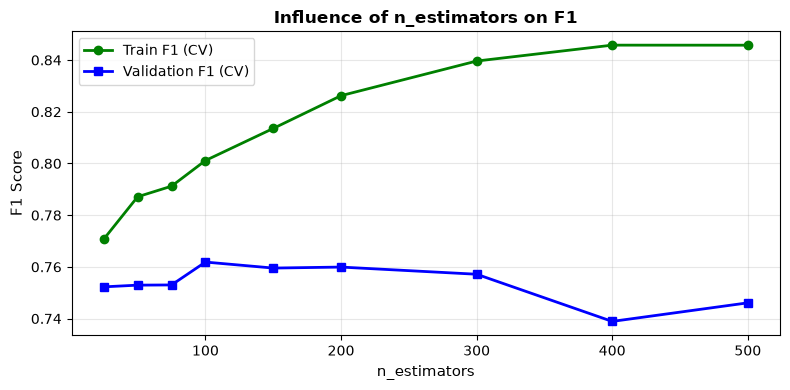

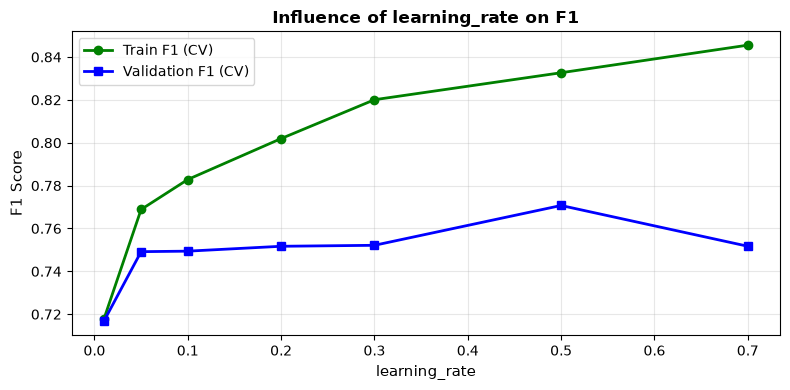

In [206]:
BASE_LEARNING_RATE = 0.5
BASE_MAX_DEPTH = 1
BASE_ESTIMATORS = 275
BASE_SUB_SAMPLE = 0.9
base_params = {
    "learning_rate": BASE_LEARNING_RATE,
    "max_depth": BASE_MAX_DEPTH,
    "n_estimators": BASE_ESTIMATORS,
    "subsample": BASE_SUB_SAMPLE, 
    "random_state": RANDOM_STATE
}

params_to_test = {
    "n_estimators": VALIDATION_VALS_ESTIMATORS,
    "learning_rate": VALIDATION_VALS_LEARNING_RATE
}

cv_strategy = StratifiedKFold(n_splits=FOLD_CNT, shuffle=True, random_state=42)

for param_name, param_values in params_to_test.items():
    
    train_scores = []
    val_scores = []
    
    for val in param_values:
        current_params = base_params.copy()
        current_params[param_name] = val
        
        gb.set_params(**{f"model__{k}": v for k, v in current_params.items()})
        
        cv_results = cross_validate(
            gb, X_train, y_train, 
            cv=cv_strategy, 
            scoring='f1', 
            return_train_score=True,
            n_jobs=-1
        )
        
        train_scores.append(cv_results['train_score'].mean())
        val_scores.append(cv_results['test_score'].mean())
        
    plt.figure(figsize=(8, 4))
    
    plt.plot(param_values, train_scores, label='Train F1 (CV)', color='green', marker='o', linewidth=2)
    
    plt.plot(param_values, val_scores, label='Validation F1 (CV)', color='blue', marker='s', linewidth=2)
    
    plt.title(f'Influence of {param_name} on F1', fontsize=12, fontweight='bold')
    plt.xlabel(param_name, fontsize=11)
    plt.ylabel('F1 Score', fontsize=11)
    
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

Как видно, по данных гиперпараметрам тест не обгоняет и не достигает train никогда. По количеству деревьев - до примерно 100 недообучение, до 200-300 нормально, после переобучение. По learning rate до примерно 0.4 недообучение, 0.5 - нормально, после переобучение.

## Финальная модель

In [207]:
# Chosing ranks of models

GRID_RANK = 4
RANDOM_RANK = 5

def get_model_by_rank(estimator, search_df, rank, X_train, y_train):
    idx = search_df.index[search_df['rank_test_score'] == rank]
    
    if len(idx) == 0:
        return None
    idx = idx[0]

    params = search_df.loc[idx, 'params']
    
    model = clone(estimator)
    
    model.set_params(**params)
    model.fit(X_train, y_train)
    
    return model

grid_model = get_model_by_rank(gb, results_grid, GRID_RANK, X_train, y_train)
random_model = get_model_by_rank(gb, results_random, RANDOM_RANK, X_train, y_train)
def_gb = models["gb_def"]

for name, model in (("Grid", grid_model), ("Random", random_model), ("Default", def_gb)):
    print(name)
    pred = model.predict(X_test)
    print("F1 test ", f1_score(y_test, pred))

Grid
F1 test  0.7384615384615385
Random
F1 test  0.7441860465116279
Default
F1 test  0.746031746031746


По метрике F1 полученные модели получились хуже baseline, но не сильно. Но, как видно по таблицам выше CV для найденных соответственно:

1) Grid mean F1 - 0.774070	
2) Random mean F1 - 0.769876 

А по данные прошлой ЛР для baseline имеем:

Baseline CV mean F1 - 0.7310, причём разбег там равен примерно 0.09, в это же время в найденных моделях - 0.06.

Вероятно, из-за небольшого количества данных так получилось, что на тесте наши модели чуть-чуть справились хуже, чем baseline, хоть по CV оказались лучше и стабильнее.